<a href="https://colab.research.google.com/github/aranavkumar/Veloura/blob/main/03_Veloura_Image_Quality_Agent_ipynb0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import cv2
import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt

PROJECT_ROOT = "/content/drive/MyDrive/Veloura_Project"

TRAIN_IMAGE_DIR = os.path.join(
    PROJECT_ROOT,
    "datasets/training/extracted/Health/training/images"
)

EVAL_IMAGE_DIR = os.path.join(
    PROJECT_ROOT,
    "datasets/evaluation/extracted/Health/eval/images"
)

TRAIN_METADATA_PATH = os.path.join(
    PROJECT_ROOT,
    "datasets/training/extracted/Health/training/metadata.csv"
)

EVAL_METADATA_PATH = os.path.join(
    PROJECT_ROOT,
    "datasets/evaluation/extracted/Health/eval/metadata.csv"
)

REPORT_DIR = os.path.join(
    PROJECT_ROOT,
    "reports/image_quality"
)

OUTPUT_DIR = os.path.join(
    PROJECT_ROOT,
    "outputs/agent_logs"
)

os.makedirs(REPORT_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

assert os.path.isdir(TRAIN_IMAGE_DIR), "Training image folder not found"
assert os.path.isdir(EVAL_IMAGE_DIR), "Evaluation image folder not found"

train_metadata = pd.read_csv(TRAIN_METADATA_PATH)
eval_metadata = pd.read_csv(EVAL_METADATA_PATH)

print("Veloura Image Quality Agent environment ready!")
print("Training images:", len(train_metadata))
print("Evaluation images:", len(eval_metadata))
print("OpenCV version:", cv2.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Veloura_Project/datasets/training/extracted/Health/training/metadata.csv'

In [ ]:
import os

PROJECT_ROOT = "/content/drive/MyDrive/Veloura_Project"

folders = {
    "Training extracted": os.path.join(
        PROJECT_ROOT, "datasets/training/extracted"
    ),
    "Evaluation extracted": os.path.join(
        PROJECT_ROOT, "datasets/evaluation/extracted"
    )
}

for name, folder in folders.items():

    print("\n==========", name, "==========")
    print("Folder exists:", os.path.exists(folder))

    for root, dirs, files in os.walk(folder):
        print("\nLocation:", root)
        print("Files:", files[:10])
        print("Subfolders:", dirs[:10])


========== Training extracted ==========
Folder exists: True

Location: /content/drive/MyDrive/Veloura_Project/datasets/training/extracted
Files: []
Subfolders: ['Health']

Location: /content/drive/MyDrive/Veloura_Project/datasets/training/extracted/Health
Files: []
Subfolders: ['training']

Location: /content/drive/MyDrive/Veloura_Project/datasets/training/extracted/Health/training
Files: []
Subfolders: ['images']

Location: /content/drive/MyDrive/Veloura_Project/datasets/training/extracted/Health/training/images
Files: ['ISIC_0033084.jpg', 'ISIC_0026038.jpg', 'ISIC_0029226.jpg', 'ISIC_0029549.jpg', 'ISIC_0024359.jpg', 'ISIC_0032589.jpg', 'ISIC_0025052.jpg', 'ISIC_0025671.jpg', 'ISIC_0030195.jpg', 'ISIC_0029497.jpg']
Subfolders: []

========== Evaluation extracted ==========
Folder exists: True

Location: /content/drive/MyDrive/Veloura_Project/datasets/evaluation/extracted
Files: ['README.md', 'manifest.json']
Subfolders: ['Health']

Location: /content/drive/MyDrive/Veloura_Project/d

In [ ]:
import os

PROJECT_ROOT = "/content/drive/MyDrive/Veloura_Project"

EVAL_EXTRACTED = os.path.join(
    PROJECT_ROOT,
    "datasets/evaluation/extracted"
)

print("Checking evaluation extraction folder:")
print(EVAL_EXTRACTED)
print("Exists:", os.path.exists(EVAL_EXTRACTED))

print("\nFolder contents:")

for root, dirs, files in os.walk(EVAL_EXTRACTED):
    print("\nLocation:", root)
    print("Subfolders:", dirs[:10])
    print("Files:", files[:10])

    if root.count(os.sep) - EVAL_EXTRACTED.count(os.sep) >= 4:
        dirs[:] = []

Checking evaluation extraction folder:
/content/drive/MyDrive/Veloura_Project/datasets/evaluation/extracted
Exists: True

Folder contents:

Location: /content/drive/MyDrive/Veloura_Project/datasets/evaluation/extracted
Subfolders: []
Files: []


In [ ]:
import os
import zipfile

PROJECT_ROOT = "/content/drive/MyDrive/Veloura_Project"

EVAL_ZIP = os.path.join(
    PROJECT_ROOT,
    "datasets/evaluation/health-eval.zip"
)

EVAL_EXTRACTED = os.path.join(
    PROJECT_ROOT,
    "datasets/evaluation/extracted"
)

# Confirm original ZIP exists
if not os.path.isfile(EVAL_ZIP):
    raise FileNotFoundError(
        f"Evaluation ZIP not found: {EVAL_ZIP}"
    )

print("ZIP found:", EVAL_ZIP)
print("ZIP size:", round(os.path.getsize(EVAL_ZIP) / (1024**2), 2), "MB")

# Verify archive before extraction
with zipfile.ZipFile(EVAL_ZIP, "r") as archive:
    bad_file = archive.testzip()

    if bad_file:
        raise ValueError(f"Corrupted archive member: {bad_file}")

    print("ZIP integrity check passed.")

    # Extract files
    archive.extractall(EVAL_EXTRACTED)

print("\nEvaluation extraction completed!")

ZIP found: /content/drive/MyDrive/Veloura_Project/datasets/evaluation/health-eval.zip
ZIP size: 509.22 MB
ZIP integrity check passed.

Evaluation extraction completed!


In [ ]:
import os

EVAL_IMAGE_DIR = os.path.join(
    EVAL_EXTRACTED,
    "Health",
    "eval",
    "images"
)

EVAL_METADATA_PATH = os.path.join(
    EVAL_EXTRACTED,
    "Health",
    "eval",
    "metadata.csv"
)

print("Evaluation image folder exists:",
      os.path.isdir(EVAL_IMAGE_DIR))

print("Evaluation metadata exists:",
      os.path.isfile(EVAL_METADATA_PATH))

if os.path.isdir(EVAL_IMAGE_DIR):
    images = [
        f for f in os.listdir(EVAL_IMAGE_DIR)
        if f.lower().endswith(".jpg")
    ]
    print("Number of evaluation images:", len(images))

Evaluation image folder exists: True
Evaluation metadata exists: True
Number of evaluation images: 1942


In [ ]:
import os

PROJECT_ROOT = "/content/drive/MyDrive/Veloura_Project"

folders = {
    "Training extracted": os.path.join(
        PROJECT_ROOT, "datasets/training/extracted"
    ),
    "Evaluation extracted": os.path.join(
        PROJECT_ROOT, "datasets/evaluation/extracted"
    )
}

for name, folder in folders.items():

    print("\n==========", name, "==========")
    print("Folder exists:", os.path.exists(folder))

    for root, dirs, files in os.walk(folder):
        print("\nLocation:", root)
        print("Files:", files[:10])
        print("Subfolders:", dirs[:10])


========== Training extracted ==========
Folder exists: True

Location: /content/drive/MyDrive/Veloura_Project/datasets/training/extracted
Files: []
Subfolders: ['Health']

Location: /content/drive/MyDrive/Veloura_Project/datasets/training/extracted/Health
Files: []
Subfolders: ['training']

Location: /content/drive/MyDrive/Veloura_Project/datasets/training/extracted/Health/training
Files: []
Subfolders: ['images']

Location: /content/drive/MyDrive/Veloura_Project/datasets/training/extracted/Health/training/images
Files: ['ISIC_0033084.jpg', 'ISIC_0026038.jpg', 'ISIC_0029226.jpg', 'ISIC_0029549.jpg', 'ISIC_0024359.jpg', 'ISIC_0032589.jpg', 'ISIC_0025052.jpg', 'ISIC_0025671.jpg', 'ISIC_0030195.jpg', 'ISIC_0029497.jpg']
Subfolders: []

========== Evaluation extracted ==========
Folder exists: True

Location: /content/drive/MyDrive/Veloura_Project/datasets/evaluation/extracted
Files: ['README.md', 'manifest.json']
Subfolders: ['Health']

Location: /content/drive/MyDrive/Veloura_Project/d

In [ ]:
import os
import zipfile

TRAIN_ZIP = os.path.join(
    PROJECT_ROOT,
    "datasets/training/health-training.zip"
)

TRAIN_EXTRACTED = os.path.join(
    PROJECT_ROOT,
    "datasets/training/extracted"
)

with zipfile.ZipFile(TRAIN_ZIP, "r") as archive:

    bad_file = archive.testzip()

    if bad_file:
        raise ValueError(f"Corrupted file: {bad_file}")

    archive.extractall(TRAIN_EXTRACTED)

print("Training dataset extraction completed!")

Training dataset extraction completed!


In [ ]:
TRAIN_EXTRACTED = os.path.join(
    PROJECT_ROOT, "datasets/training/extracted"
)

EVAL_EXTRACTED = os.path.join(
    PROJECT_ROOT, "datasets/evaluation/extracted"
)

TRAIN_IMAGE_DIR = os.path.join(
    TRAIN_EXTRACTED, "Health/training/images"
)

EVAL_IMAGE_DIR = os.path.join(
    EVAL_EXTRACTED, "Health/eval/images"
)

TRAIN_METADATA_PATH = os.path.join(
    TRAIN_EXTRACTED, "Health/training/metadata.csv"
)

EVAL_METADATA_PATH = os.path.join(
    EVAL_EXTRACTED, "Health/eval/metadata.csv"
)

print("TRAIN IMAGE FOLDER:", os.path.isdir(TRAIN_IMAGE_DIR))
print("EVAL IMAGE FOLDER:", os.path.isdir(EVAL_IMAGE_DIR))

print("TRAIN METADATA:", os.path.isfile(TRAIN_METADATA_PATH))
print("EVAL METADATA:", os.path.isfile(EVAL_METADATA_PATH))

TRAIN IMAGE FOLDER: True
EVAL IMAGE FOLDER: True
TRAIN METADATA: True
EVAL METADATA: True


In [ ]:
import pandas as pd

train_metadata = pd.read_csv(TRAIN_METADATA_PATH)
eval_metadata = pd.read_csv(EVAL_METADATA_PATH)

print("Veloura environment ready!")
print("Training images:", len(train_metadata))
print("Evaluation images:", len(eval_metadata))

Veloura environment ready!
Training images: 7762
Evaluation images: 1942


In [ ]:

import cv2
import numpy as np
import os


class ImageQualityAgent:

    def __init__(self):

        self.min_resolution = 224
        self.blur_threshold = 50.0
        self.min_brightness = 35.0
        self.max_brightness = 220.0
        self.min_contrast = 25.0
        self.max_glare_fraction = 0.15

    def analyze(self, image_path):

        # Check image existence
        if not os.path.isfile(image_path):
            return {
                "status": "INVALID",
                "quality_score": 0,
                "issues": ["IMAGE_FILE_NOT_FOUND"],
                "recommendation": "RE_IMAGE"
            }

        # Read image
        image = cv2.imread(image_path)

        if image is None:
            return {
                "status": "INVALID",
                "quality_score": 0,
                "issues": ["IMAGE_COULD_NOT_BE_OPENED"],
                "recommendation": "RE_IMAGE"
            }

        # Convert to grayscale
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        height, width = gray.shape

        # 1. Blur measurement
        blur_score = float(
            cv2.Laplacian(gray, cv2.CV_64F).var()
        )

        # 2. Brightness
        brightness = float(np.mean(gray))

        # 3. Contrast
        contrast = float(np.std(gray))

        # 4. Possible glare
        glare_fraction = float(np.mean(gray >= 245))

        # 5. Quality scoring
        issues = []
        score = 100

        if min(width, height) < self.min_resolution:
            issues.append("LOW_RESOLUTION")
            score -= 20

        if blur_score < self.blur_threshold:
            issues.append("POSSIBLE_BLUR")
            score -= 25

        if brightness < self.min_brightness:
            issues.append("UNDEREXPOSED")
            score -= 20

        elif brightness > self.max_brightness:
            issues.append("OVEREXPOSED")
            score -= 20

        if contrast < self.min_contrast:
            issues.append("LOW_CONTRAST")
            score -= 15

        if glare_fraction > self.max_glare_fraction:
            issues.append("POSSIBLE_GLARE")
            score -= 20

        score = max(0, score)

        # 6. Conservative prototype decision policy
        severe_issues = [
            "LOW_RESOLUTION",
            "UNDEREXPOSED",
            "OVEREXPOSED"
        ]

        if (
            blur_score < 20
            or any(issue in issues for issue in severe_issues)
        ):
            status = "FAIL"
            recommendation = "RE_IMAGE"

        elif len(issues) > 0:
            status = "REVIEW"
            recommendation = "MANUAL_REVIEW"

        else:
            status = "PASS"
            recommendation = "PROCEED_TO_NEXT_AGENT"

        # 7. Structured agent output
        return {
            "status": status,
            "quality_score": score,
            "width": width,
            "height": height,
            "blur_score": round(blur_score, 2),
            "brightness": round(brightness, 2),
            "contrast": round(contrast, 2),
            "glare_fraction": round(glare_fraction, 4),
            "issues": issues,
            "recommendation": recommendation
        }


# Initialize agent
quality_agent = ImageQualityAgent()

print("=" * 50)
print("VELOURA IMAGE QUALITY AGENT")
print("=" * 50)
print("Agent initialized successfully!")
print("Blur detection: Enabled")
print("Brightness analysis: Enabled")
print("Contrast analysis: Enabled")
print("Glare detection: Enabled")
print("Resolution checking: Enabled")
print("Quality scoring: Enabled")
print("Safety-oriented review rules: Enabled")
print("=" * 50)


VELOURA IMAGE QUALITY AGENT
Agent initialized successfully!
Blur detection: Enabled
Brightness analysis: Enabled
Contrast analysis: Enabled
Glare detection: Enabled
Resolution checking: Enabled
Quality scoring: Enabled
Safety-oriented review rules: Enabled


In [ ]:

import os
import cv2
import matplotlib.pyplot as plt

# Select one image from training metadata
sample = train_metadata.iloc[0]

sample_image_id = sample["image_id"]

sample_image_path = os.path.join(
    TRAIN_IMAGE_DIR,
    sample_image_id + ".jpg"
)

# Run Image Quality Agent
result = quality_agent.analyze(sample_image_path)

# Display agent report
print("=" * 55)
print("VELOURA - IMAGE QUALITY AGENT REPORT")
print("=" * 55)

print("Image ID:", sample_image_id)

for key, value in result.items():
    print(f"{key}: {value}")

print("=" * 55)


VELOURA - IMAGE QUALITY AGENT REPORT
Image ID: ISIC_0027419
status: REVIEW
quality_score: 85
width: 600
height: 450
blur_score: 62.19
brightness: 178.64
contrast: 18.18
glare_fraction: 0.0
issues: ['LOW_CONTRAST']
recommendation: MANUAL_REVIEW


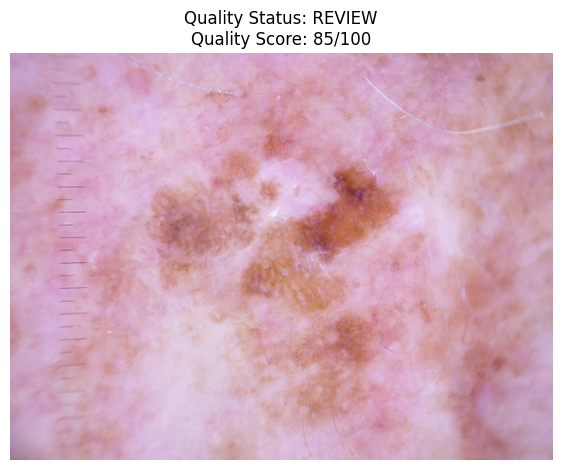

In [ ]:

image = cv2.imread(sample_image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(7, 7))
plt.imshow(image_rgb)

plt.title(
    f"Quality Status: {result['status']}\n"
    f"Quality Score: {result['quality_score']}/100"
)

plt.axis("off")
plt.show()


In [ ]:

from tqdm.auto import tqdm
import pandas as pd
import os

# Select up to 15 images per class
# This gives a balanced preliminary sample.

sample_metadata = (
    train_metadata
    .groupby("dx", group_keys=False)
    .apply(
        lambda group: group.sample(
            n=min(15, len(group)),
            random_state=42
        ),
        include_groups=True
    )
    .reset_index(drop=True)
)

print("Selected images:", len(sample_metadata))
print("\nImages selected per class:")
print(sample_metadata["dx"].value_counts())

# Run Image Quality Agent
quality_records = []

for _, row in tqdm(
    sample_metadata.iterrows(),
    total=len(sample_metadata),
    desc="Testing Image Quality Agent"
):

    image_id = row["image_id"]

    image_path = os.path.join(
        TRAIN_IMAGE_DIR,
        image_id + ".jpg"
    )

    report = quality_agent.analyze(image_path)

    quality_records.append({
        "image_id": image_id,
        "dx": row["dx"],
        **report
    })

quality_test_df = pd.DataFrame(quality_records)

print("\n100-IMAGE TEST COMPLETED!")
print("Total analysed:", len(quality_test_df))


Selected images: 105

Images selected per class:
dx
akiec    15
bcc      15
bkl      15
df       15
mel      15
nv       15
vasc     15
Name: count, dtype: int64


/tmp/ipykernel_1154/2609042588.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


Testing Image Quality Agent:   0%|          | 0/105 [00:00<?, ?it/s]


100-IMAGE TEST COMPLETED!
Total analysed: 105


In [ ]:

print("========== QUALITY AGENT RESULTS ==========")

print("\nSTATUS DISTRIBUTION:")
print(quality_test_df["status"].value_counts())

print("\nRECOMMENDATION DISTRIBUTION:")
print(quality_test_df["recommendation"].value_counts())

print("\nAVERAGE QUALITY SCORE:")
print(round(quality_test_df["quality_score"].mean(), 2))

print("\nCLASS-WISE QUALITY RESULTS:")

print(
    quality_test_df.groupby("dx").agg(
        total_images=("image_id", "count"),
        average_score=("quality_score", "mean"),
        pass_count=("status", lambda x: (x == "PASS").sum()),
        review_count=("status", lambda x: (x == "REVIEW").sum()),
        fail_count=("status", lambda x: (x == "FAIL").sum())
    ).round(2)
)


========== QUALITY AGENT RESULTS ==========

STATUS DISTRIBUTION:
status
REVIEW    69
PASS      29
FAIL       7
Name: count, dtype: int64

RECOMMENDATION DISTRIBUTION:
recommendation
MANUAL_REVIEW            69
PROCEED_TO_NEXT_AGENT    29
RE_IMAGE                  7
Name: count, dtype: int64

AVERAGE QUALITY SCORE:
81.05

CLASS-WISE QUALITY RESULTS:
       total_images  average_score  pass_count  review_count  fail_count
dx                                                                      
akiec            15          80.00           4            10           1
bcc              15          76.67           4            10           1
bkl              15          85.33           5            10           0
df               15          84.00           3            11           1
mel              15          87.00           7             8           0
nv               15          69.00           1            12           2
vasc             15          85.33           5             8    

In [ ]:

quality_issues = [
    "LOW_RESOLUTION",
    "POSSIBLE_BLUR",
    "UNDEREXPOSED",
    "OVEREXPOSED",
    "LOW_CONTRAST",
    "POSSIBLE_GLARE"
]

print("========== DETECTED QUALITY ISSUES ==========")

for issue in quality_issues:

    count = quality_test_df["issues"].apply(
        lambda issues: issue in issues
    ).sum()

    percentage = count / len(quality_test_df) * 100

    print(
        f"{issue}: {count} images ({percentage:.1f}%)"
    )


========== DETECTED QUALITY ISSUES ==========
LOW_RESOLUTION: 0 images (0.0%)
POSSIBLE_BLUR: 42 images (40.0%)
UNDEREXPOSED: 0 images (0.0%)
OVEREXPOSED: 1 images (1.0%)
LOW_CONTRAST: 60 images (57.1%)
POSSIBLE_GLARE: 1 images (1.0%)


In [ ]:

import os

REPORT_DIR = os.path.join(
    PROJECT_ROOT,
    "reports",
    "image_quality"
)

os.makedirs(REPORT_DIR, exist_ok=True)

output_path = os.path.join(
    REPORT_DIR,
    "image_quality_105_sample_test.csv"
)

quality_test_df.to_csv(
    output_path,
    index=False
)

print("Test results saved successfully!")
print("Location:", output_path)


Test results saved successfully!
Location: /content/drive/MyDrive/Veloura_Project/reports/image_quality/image_quality_105_sample_test.csv


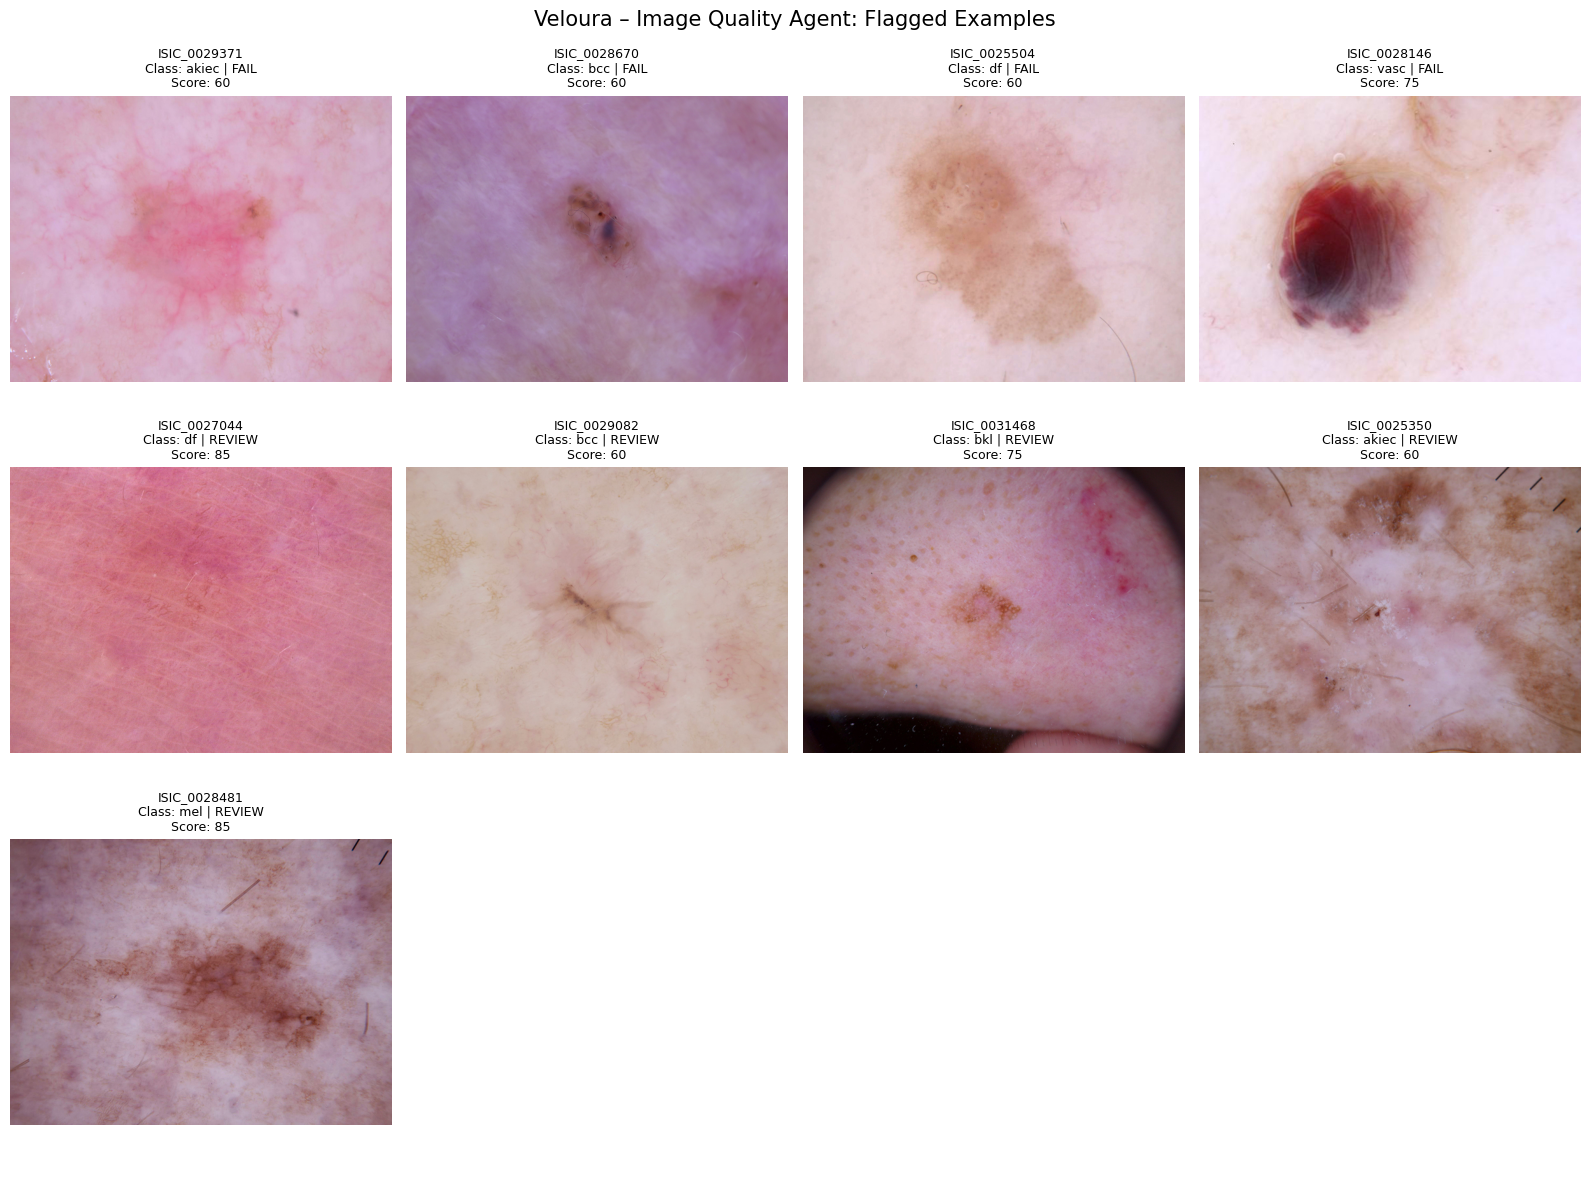

In [ ]:

import matplotlib.pyplot as plt
import cv2
import os
import pandas as pd

# Select examples of different quality problems
blur_examples = quality_test_df[
    quality_test_df["issues"].apply(
        lambda x: "POSSIBLE_BLUR" in x
    )
].nsmallest(3, "blur_score")

contrast_examples = quality_test_df[
    quality_test_df["issues"].apply(
        lambda x: "LOW_CONTRAST" in x
    )
].nsmallest(3, "contrast")

fail_examples = quality_test_df[
    quality_test_df["status"] == "FAIL"
].head(3)

review_examples = quality_test_df[
    quality_test_df["status"] == "REVIEW"
].sample(
    min(3, len(quality_test_df[
        quality_test_df["status"] == "REVIEW"
    ])),
    random_state=42
)

examples = pd.concat([
    fail_examples,
    blur_examples,
    contrast_examples,
    review_examples
]).drop_duplicates("image_id").head(12)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for ax, (_, row) in zip(axes, examples.iterrows()):

    image_path = os.path.join(
        TRAIN_IMAGE_DIR,
        row["image_id"] + ".jpg"
    )

    image = cv2.imread(image_path)

    if image is not None:
        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        ax.imshow(image)

    ax.set_title(
        f"{row['image_id']}\n"
        f"Class: {row['dx']} | {row['status']}\n"
        f"Score: {row['quality_score']}",
        fontsize=9
    )

    ax.axis("off")

for ax in axes[len(examples):]:
    ax.axis("off")

plt.suptitle(
    "Veloura – Image Quality Agent: Flagged Examples",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [ ]:

failed_images = quality_test_df[
    quality_test_df["status"] == "FAIL"
]

display(
    failed_images[
        [
            "image_id",
            "dx",
            "quality_score",
            "blur_score",
            "brightness",
            "contrast",
            "issues",
            "recommendation"
        ]
    ]
)


,image_id,dx,quality_score,blur_score,brightness,contrast,issues,recommendation
2,ISIC_0029371,akiec,60,13.37,181.46,10.52,"[POSSIBLE_BLUR, LOW_CONTRAST]",RE_IMAGE
17,ISIC_0028670,bcc,60,12.72,139.53,12.11,"[POSSIBLE_BLUR, LOW_CONTRAST]",RE_IMAGE
47,ISIC_0025504,df,60,13.12,194.56,14.90,"[POSSIBLE_BLUR, LOW_CONTRAST]",RE_IMAGE
78,ISIC_0028761,nv,60,16.11,154.13,17.02,"[POSSIBLE_BLUR, LOW_CONTRAST]",RE_IMAGE
80,ISIC_0033136,nv,60,16.00,145.67,21.23,"[POSSIBLE_BLUR, LOW_CONTRAST]",RE_IMAGE
92,ISIC_0029404,vasc,60,198.68,227.07,41.71,"[OVEREXPOSED, POSSIBLE_GLARE]",RE_IMAGE
97,ISIC_0028146,vasc,75,10.08,195.17,49.04,[POSSIBLE_BLUR],RE_IMAGE


In [ ]:

import os
import pandas as pd
import cv2
import numpy as np
from tqdm.auto import tqdm

# Reconnect Google Drive if necessary
from google.colab import drive
drive.mount('/content/drive')

# Project paths
PROJECT_ROOT = "/content/drive/MyDrive/Veloura_Project"

TRAIN_EXTRACTED = os.path.join(
    PROJECT_ROOT,
    "datasets/training/extracted"
)

TRAIN_IMAGE_DIR = os.path.join(
    TRAIN_EXTRACTED,
    "Health/training/images"
)

TRAIN_METADATA_PATH = os.path.join(
    TRAIN_EXTRACTED,
    "Health/training/metadata.csv"
)

REPORT_DIR = os.path.join(
    PROJECT_ROOT,
    "reports/image_quality"
)

OUTPUT_DIR = os.path.join(
    PROJECT_ROOT,
    "outputs/agent_logs"
)

os.makedirs(REPORT_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Reload training metadata
train_metadata = pd.read_csv(TRAIN_METADATA_PATH)

# Verify paths
assert os.path.isdir(TRAIN_IMAGE_DIR), "Training images not found!"
assert len(train_metadata) == 7762, "Unexpected metadata count!"

print("Training metadata loaded successfully!")
print("Training records:", len(train_metadata))
print("Training image folder:", os.path.isdir(TRAIN_IMAGE_DIR))
print("Image Quality Agent available:", "quality_agent" in globals())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training metadata loaded successfully!
Training records: 7762
Training image folder: True
Image Quality Agent available: False


In [ ]:

from tqdm.auto import tqdm
import pandas as pd
import os

full_quality_records = []

for _, row in tqdm(
    train_metadata.iterrows(),
    total=len(train_metadata),
    desc="Veloura Image Quality Agent"
):

    image_id = row["image_id"]

    image_path = os.path.join(
        TRAIN_IMAGE_DIR,
        image_id + ".jpg"
    )

    report = quality_agent.analyze(image_path)

    full_quality_records.append({
        "image_id": image_id,
        **report
    })

full_quality_df = pd.DataFrame(full_quality_records)

print("\nFULL TRAINING ANALYSIS COMPLETED")
print("Total images:", len(full_quality_df))
print("Unique image IDs:", full_quality_df["image_id"].nunique())


Veloura Image Quality Agent:   0%|          | 0/7762 [00:00<?, ?it/s]


FULL TRAINING ANALYSIS COMPLETED
Total images: 7762
Unique image IDs: 7762


In [ ]:

import cv2
import numpy as np
import os

class ImageQualityAgent:

    def __init__(self):
        self.min_resolution = 224
        self.blur_threshold = 50.0
        self.min_brightness = 35.0
        self.max_brightness = 220.0
        self.min_contrast = 25.0
        self.max_glare_fraction = 0.15

    def analyze(self, image_path):

        if not os.path.isfile(image_path):
            return {
                "status": "INVALID",
                "quality_score": 0,
                "issues": ["IMAGE_FILE_NOT_FOUND"],
                "recommendation": "RE_IMAGE"
            }

        image = cv2.imread(image_path)

        if image is None:
            return {
                "status": "INVALID",
                "quality_score": 0,
                "issues": ["IMAGE_COULD_NOT_BE_OPENED"],
                "recommendation": "RE_IMAGE"
            }

        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        height, width = gray.shape

        blur_score = float(
            cv2.Laplacian(gray, cv2.CV_64F).var()
        )

        brightness = float(np.mean(gray))
        contrast = float(np.std(gray))
        glare_fraction = float(np.mean(gray >= 245))

        issues = []
        score = 100

        if min(width, height) < self.min_resolution:
            issues.append("LOW_RESOLUTION")
            score -= 20

        if blur_score < self.blur_threshold:
            issues.append("POSSIBLE_BLUR")
            score -= 25

        if brightness < self.min_brightness:
            issues.append("UNDEREXPOSED")
            score -= 20

        elif brightness > self.max_brightness:
            issues.append("OVEREXPOSED")
            score -= 20

        if contrast < self.min_contrast:
            issues.append("LOW_CONTRAST")
            score -= 15

        if glare_fraction > self.max_glare_fraction:
            issues.append("POSSIBLE_GLARE")
            score -= 20

        score = max(0, score)

        severe_issues = [
            "LOW_RESOLUTION",
            "UNDEREXPOSED",
            "OVEREXPOSED"
        ]

        if (
            blur_score < 20
            or any(issue in issues for issue in severe_issues)
        ):
            status = "FAIL"
            recommendation = "RE_IMAGE"

        elif len(issues) > 0:
            status = "REVIEW"
            recommendation = "MANUAL_REVIEW"

        else:
            status = "PASS"
            recommendation = "PROCEED_TO_NEXT_AGENT"

        return {
            "status": status,
            "quality_score": score,
            "width": width,
            "height": height,
            "blur_score": round(blur_score, 2),
            "brightness": round(brightness, 2),
            "contrast": round(contrast, 2),
            "glare_fraction": round(glare_fraction, 4),
            "issues": issues,
            "recommendation": recommendation
        }


# Create agent object again
quality_agent = ImageQualityAgent()

print("Image Quality Agent reinitialized successfully!")


Image Quality Agent reinitialized successfully!


In [ ]:
print("Training records:", len(train_metadata))
print("Agent initialized:", isinstance(quality_agent, ImageQualityAgent))

test_path = os.path.join(
    TRAIN_IMAGE_DIR,
    train_metadata.iloc[0]["image_id"] + ".jpg"
)

print("\nTest agent output:")
print(quality_agent.analyze(test_path))

Training records: 7762
Agent initialized: True

Test agent output:
{'status': 'REVIEW', 'quality_score': 85, 'width': 600, 'height': 450, 'blur_score': 62.19, 'brightness': 178.64, 'contrast': 18.18, 'glare_fraction': 0.0, 'issues': ['LOW_CONTRAST'], 'recommendation': 'MANUAL_REVIEW'}


In [ ]:
print("========== VELOURA QUALITY REPORT ==========")

print("\nSTATUS DISTRIBUTION:")
print(full_quality_df["status"].value_counts())

print("\nRECOMMENDATION DISTRIBUTION:")
print(full_quality_df["recommendation"].value_counts())

print("\nAVERAGE QUALITY SCORE:")
print(round(full_quality_df["quality_score"].mean(), 2))

print("\nQUALITY ISSUES:")

all_issues = [
    "LOW_RESOLUTION",
    "POSSIBLE_BLUR",
    "UNDEREXPOSED",
    "OVEREXPOSED",
    "LOW_CONTRAST",
    "POSSIBLE_GLARE"
]

for issue in all_issues:
    count = full_quality_df["issues"].apply(
        lambda x: issue in x
    ).sum()

    percentage = count / len(full_quality_df) * 100

    print(f"{issue}: {count} ({percentage:.2f}%)")

print("\n============================================")

========== VELOURA QUALITY REPORT ==========

STATUS DISTRIBUTION:
status
REVIEW    5113
PASS      2367
FAIL       282
Name: count, dtype: int64

RECOMMENDATION DISTRIBUTION:
recommendation
MANUAL_REVIEW            5113
PROCEED_TO_NEXT_AGENT    2367
RE_IMAGE                  282
Name: count, dtype: int64

AVERAGE QUALITY SCORE:
80.45

QUALITY ISSUES:
LOW_RESOLUTION: 0 (0.00%)
POSSIBLE_BLUR: 3926 (50.58%)
UNDEREXPOSED: 0 (0.00%)
OVEREXPOSED: 7 (0.09%)
LOW_CONTRAST: 3555 (45.80%)
POSSIBLE_GLARE: 6 (0.08%)



In [ ]:

import os

# Create report directories
REPORT_DIR = os.path.join(
    PROJECT_ROOT,
    "reports",
    "image_quality"
)

OUTPUT_DIR = os.path.join(
    PROJECT_ROOT,
    "outputs",
    "agent_logs"
)

os.makedirs(REPORT_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Save results as CSV
csv_path = os.path.join(
    REPORT_DIR,
    "full_training_quality_report.csv"
)

full_quality_df.to_csv(
    csv_path,
    index=False
)

# Save results as JSON
json_path = os.path.join(
    OUTPUT_DIR,
    "image_quality_agent_logs.json"
)

full_quality_df.to_json(
    json_path,
    orient="records",
    indent=2
)

print("==========================================")
print("VELOURA - QUALITY REPORTS SAVED")
print("==========================================")

print("CSV report:")
print(csv_path)

print("\nJSON agent logs:")
print(json_path)

print("\nTotal records saved:", len(full_quality_df))

print("\nSaving completed successfully!")
print("==========================================")


VELOURA - QUALITY REPORTS SAVED
CSV report:
/content/drive/MyDrive/Veloura_Project/reports/image_quality/full_training_quality_report.csv

JSON agent logs:
/content/drive/MyDrive/Veloura_Project/outputs/agent_logs/image_quality_agent_logs.json

Total records saved: 7762

Saving completed successfully!


In [ ]:
print("Total metadata images:", len(train_metadata))
print("Total quality reports:", len(full_quality_df))
print("Unique quality report IDs:",
      full_quality_df["image_id"].nunique())

print("Missing reports:",
      set(train_metadata["image_id"]) -
      set(full_quality_df["image_id"]))

print("Duplicate reports:",
      full_quality_df["image_id"].duplicated().sum())

Total metadata images: 7762
Total quality reports: 7762
Unique quality report IDs: 7762
Missing reports: set()
Duplicate reports: 0
